# 12 · Mini project and recap

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/12_mini_project_and_recap.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 12 of 12*

Time to put the whole course together. In this capstone we build an **SMS spam filter end to end**: from
raw text, through a clean experimental protocol (de-duplication, a locked-away test set, baselines,
cross-validated model selection), to a final one-shot evaluation, error analysis, an interpretable model
and a saved pipeline that classifies new messages. We finish with a **recap of every representation and
model in the course** and pointers to what comes next.

### Learning objectives
By the end of this notebook you will be able to:
1. Plan and run a complete text-classification project with a protocol that avoids the pitfalls of notebook 11.
2. Combine word and character n-gram TF-IDF features in one scikit-learn `Pipeline`.
3. Select a model and its hyper-parameters with cross-validation on the training data only.
4. Evaluate once on held-out data, analyse the errors, and explain the model's decisions.
5. Save a trained pipeline, load it back and use it on new text.
6. Place every technique of the course — from one-hot vectors to word embeddings — in one picture.

## 0 · Setup

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


In [2]:
import tempfile, joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score, average_precision_score)

## 1 · The project plan
**Goal:** flag spam SMS messages while losing as few real (ham) messages as possible.

1. Load the raw data, **de-duplicate** it and lock away a stratified **test set** (20%).
2. Measure two **baselines** — always-ham and a hand-written keyword rule.
3. Compare candidate pipelines with **5-fold stratified cross-validation** on the training set, scored by spam F1.
4. Tune the best candidate with `GridSearchCV`, again on the training set only.
5. Evaluate the final model **once** on the test set; analyse the errors; explain the model.
6. Save the pipeline and use it on new messages.

## 2 · Data: de-duplicate, then split

In [3]:
raw = nlp_course.load_sms()
data = raw.drop_duplicates("text").reset_index(drop=True)
print(f"{len(raw)} messages → {len(data)} after removing {len(raw) - len(data)} exact duplicates")
data["y"] = (data["label"] == "spam").astype(int)
train, test = train_test_split(data, test_size=0.20, stratify=data["y"], random_state=42)
X_train, y_train = train["text"], train["y"].to_numpy()
X_test, y_test = test["text"], test["y"].to_numpy()
print(f"train: {len(train)} ({y_train.mean():.1%} spam)   test: {len(test)} ({y_test.mean():.1%} spam) — locked away")
print("\nTwo training messages:")
for lab in ["ham", "spam"]:
    print(f"  [{lab}]", train.loc[train["label"] == lab, "text"].iloc[0][:110])

5574 messages → 5171 after removing 403 exact duplicates
train: 4136 (12.6% spam)   test: 1035 (12.7% spam) — locked away

Two training messages:
  [ham] Sir, hope your day is going smoothly. i really hoped i wont have to bother you about this. I have some bills t
  [spam] thesmszone.com lets you send free anonymous and masked messages..im sending this message from there..do you se


## 3 · Baselines
Every model must beat something simple. A keyword rule is what a person might write before learning NLP.
Neither baseline is fitted to anything, so we can measure them on the training set and keep the test set
untouched.

In [4]:
KEYWORDS = ["free", "txt", "claim", "prize", "won", "win", "urgent", "cash", "call now", "mobile"]

def keyword_rule(texts):
    t = texts.str.lower()
    return np.column_stack([t.str.contains(k, regex=False) for k in KEYWORDS]).any(axis=1).astype(int)

def scores(y, p):
    return {"precision": precision_score(y, p, zero_division=0), "recall": recall_score(y, p),
            "F1": f1_score(y, p)}

base = pd.DataFrame({
    "always ham": scores(y_train, np.zeros_like(y_train)),
    "keyword rule": scores(y_train, keyword_rule(X_train)),
}).T.round(3)
base

,precision,recall,F1
always ham,0.000,0.000,0.000
keyword rule,0.638,0.699,0.667


The keyword rule catches about 70% of the spam, but roughly a third of the messages it flags are real
messages that happen to contain words like "free", "win" or "mobile". A learned model has to do clearly
better than this to be worth it.

## 4 · Candidate pipelines, compared by cross-validation
Each candidate is a complete `Pipeline` from raw text to prediction, so every fold re-fits the vectorizers
on its own training part (no leakage, notebook 11). Besides word TF-IDF we try **character n-grams**
(`char_wb`, 2–5 characters), which capture spellings like *FREE!!*, *£1000* or *txt* that word tokens miss.

In [5]:
def word_tfidf():
    return TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2)

def char_tfidf():
    return TfidfVectorizer(sublinear_tf=True, analyzer="char_wb", ngram_range=(2, 5), min_df=2)

def word_char():
    return FeatureUnion([("word", word_tfidf()), ("char", char_tfidf())])

candidates = {
    "NB · word":          make_pipeline(word_tfidf(), MultinomialNB(alpha=0.1)),
    "LogReg · word":      make_pipeline(word_tfidf(), LogisticRegression(C=10, max_iter=3000)),
    "SVM · word":         make_pipeline(word_tfidf(), LinearSVC(C=1.0)),
    "SVM · char":         make_pipeline(char_tfidf(), LinearSVC(C=1.0)),
    "LogReg · word+char": make_pipeline(word_char(), LogisticRegression(C=10, max_iter=3000)),
    "SVM · word+char":    make_pipeline(word_char(), LinearSVC(C=1.0)),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
rows = {}
for name, pipe in candidates.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["f1", "precision", "recall"])
    rows[name] = {"F1 mean": r["test_f1"].mean(), "F1 std": r["test_f1"].std(),
                  "precision": r["test_precision"].mean(), "recall": r["test_recall"].mean()}
cv_table = pd.DataFrame(rows).T.sort_values("F1 mean", ascending=False).round(3)
cv_table

,F1 mean,F1 std,precision,recall
SVM · word+char,0.961,0.011,0.994,0.931
LogReg · word+char,0.957,0.014,0.996,0.921
SVM · char,0.955,0.009,0.994,0.919
SVM · word,0.943,0.014,0.979,0.910
NB · word,0.939,0.012,0.987,0.895
LogReg · word,0.933,0.014,0.985,0.887


In [6]:
best_name = cv_table.index[0]
print(f"Best candidate by cross-validated spam F1: {best_name} ({cv_table.loc[best_name, 'F1 mean']:.3f} ± {cv_table.loc[best_name, 'F1 std']:.3f})")
print(f"Keyword-rule F1 on the training set:       {base.loc['keyword rule', 'F1']:.3f}")

Best candidate by cross-validated spam F1: SVM · word+char (0.961 ± 0.011)
Keyword-rule F1 on the training set:       0.667


## 5 · Tuning the best family
We tune the regularisation strength `C` of the best candidate with `GridSearchCV` — still only on the
training set. (Section 4 already showed which features work; here we only adjust the classifier.)

In [7]:
best_pipe = candidates[best_name]
clf_step = best_pipe.steps[-1][0]
grid = GridSearchCV(best_pipe, {f"{clf_step}__C": [0.3, 1, 3, 10, 30]}, cv=cv, scoring="f1")
grid.fit(X_train, y_train)
print("best C:", grid.best_params_, f"  cross-validated F1: {grid.best_score_:.3f}")
print(pd.Series(grid.cv_results_["mean_test_score"], index=[p[f"{clf_step}__C"] for p in grid.cv_results_["params"]],
                name="CV F1 by C").round(3).to_string())
final = grid.best_estimator_

best C: {'linearsvc__C': 10}   cross-validated F1: 0.962
0.3     0.958
1.0     0.961
3.0     0.961
10.0    0.962
30.0    0.962


## 6 · The final evaluation — once
The test set has not been touched by any decision so far. We now evaluate the chosen pipeline on it once.

In [8]:
pred = final.predict(X_test)
print(classification_report(y_test, pred, target_names=["ham", "spam"], digits=3))
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Real messages wrongly flagged as spam: {fp} of {tn + fp}")
print(f"Spam messages that got through:        {fn} of {fn + tp}")
print(f"Keyword rule on the same test set:     F1 {f1_score(y_test, keyword_rule(X_test)):.3f}")

              precision    recall  f1-score   support

         ham      0.990     0.999     0.994       904
        spam      0.992     0.931     0.961       131

    accuracy                          0.990      1035
   macro avg      0.991     0.965     0.978      1035
weighted avg      0.990     0.990     0.990      1035

Real messages wrongly flagged as spam: 1 of 904
Spam messages that got through:        9 of 131
Keyword rule on the same test set:     F1 0.659


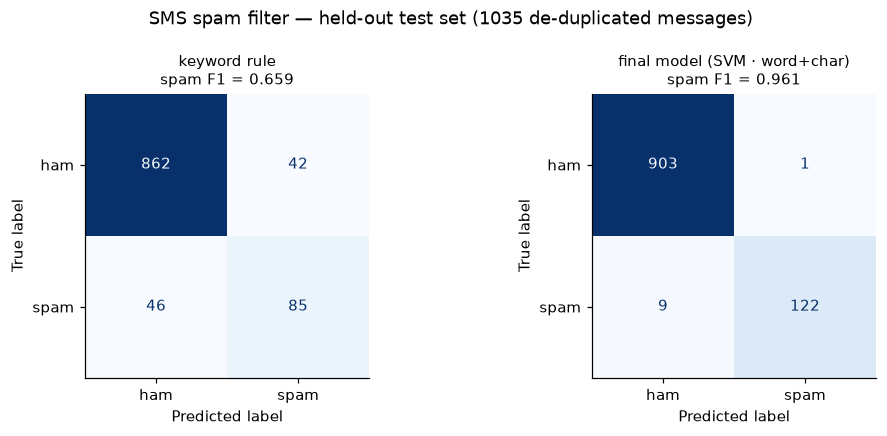

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for ax, (title, p) in zip(axes, [("keyword rule", keyword_rule(X_test)), (f"final model ({best_name})", pred)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{title}\nspam F1 = {f1_score(y_test, p):.3f}", fontsize=10)
fig.suptitle(f"SMS spam filter — held-out test set ({len(y_test)} de-duplicated messages)")
fig.tight_layout()
fig.savefig(DOCS / "12_final_confusion.png", bbox_inches="tight")
plt.show()

## 7 · Error analysis
Numbers tell us *how often* the model fails; reading the errors tells us *why*.

In [10]:
import re
# A few spam messages in this public dataset contain explicit words; we mask them when printing.
EXPLICIT = re.compile(r"\b(bitch|shit|fuck\w*|sexy|xxx|nasty|filthy\w*)\b", re.I)
show = lambda t: EXPLICIT.sub("***", t)[:120]
err = test.assign(pred=pred)
print("FALSE POSITIVES (ham flagged as spam):")
for t in err.loc[(err["y"] == 0) & (err["pred"] == 1), "text"]:
    print("  •", show(t))
print("\nFALSE NEGATIVES (spam that got through):")
for t in err.loc[(err["y"] == 1) & (err["pred"] == 0), "text"]:
    print("  •", show(t))

FALSE POSITIVES (ham flagged as spam):
  • I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to  &lt;#

FALSE NEGATIVES (spam that got through):
  • Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola 
  • ringtoneking 84484
  • Would you like to see my *** pics they are so hot they were nearly banned in the uk!
  • Babe: U want me dont u baby! Im *** and have a thing 4 ***. Fancy a rude time with a *** ***. How about we go slo n hard
  • Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 09099726395 Lu
  • Missed call alert. These numbers called but left no message. 07008009200
  • In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C
  • ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 D

The single false positive is an automated message advertising *FREE SMS* — arguably promotional itself,
a reminder that labels are not always clear-cut. The missed spam is mostly messages that do not use the
usual prize/claim/"txt" vocabulary: a bare keyword and number, a fake "missed call alert", a quiz, a
burger promotion, a one-line joke, a complaint-style story, or chat-style adult spam. Errors like these are where more data, better features or a
different model family would have to help.

## 8 · Explaining the model
Both feature blocks are linear, so every word or character n-gram has one weight. Positive weights push
toward spam, negative toward ham.

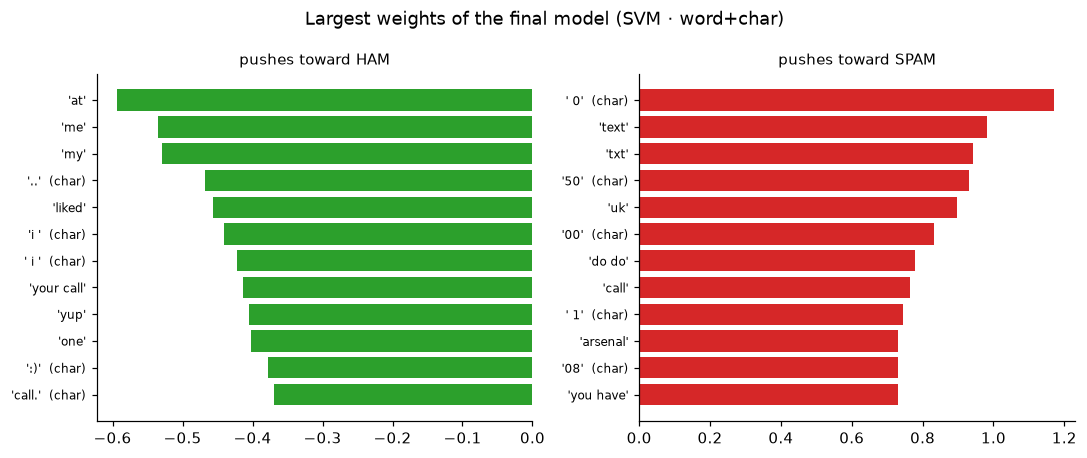

In [11]:
names = final[:-1].get_feature_names_out()
w = final[-1].coef_.ravel()
order = np.argsort(w)
top_spam, top_ham = order[::-1][:12], order[:12]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, idx, col, title in [(axes[0], top_ham, "tab:green", "pushes toward HAM"), (axes[1], top_spam, "tab:red", "pushes toward SPAM")]:
    labels = [repr(n.split("__", 1)[1]) + ("  (char)" if n.startswith("char") else "") for n in names[idx]]
    ax.barh(labels[::-1], w[idx][::-1], color=col)
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle(f"Largest weights of the final model ({best_name})")
fig.tight_layout()
fig.savefig(DOCS / "12_top_features.png", bbox_inches="tight")
plt.show()

In [12]:
n_char = sum(n.startswith("char") for n in names)
print(f"{len(names):,} features: {len(names) - n_char:,} word/bigram + {n_char:,} character n-grams")
print("Top spam features:", [n.split("__", 1)[1] for n in names[top_spam]])

43,209 features: 10,164 word/bigram + 33,045 character n-grams
Top spam features: [' 0', 'text', 'txt', '50', 'uk', '00', 'do do', 'call', ' 1', 'arsenal', '08', 'you have']


The strongest spam signals are character n-grams of **digits** (`' 0'`, `'00'`, `'08'`, `'50'` — phone
numbers, short codes and prices) and words such as *txt*, *text*, *call* and *uk*. A few features are
shortcuts: *arsenal* appears in only two de-duplicated messages, both spam (football-score and dartboard
promotions), so the model treats it as a spam word. As in notebook 10, a linear model's weights make such
shortcuts easy to spot.

## 9 · Save, load and use the pipeline
Because the whole thing is one `Pipeline`, a single file holds the vectorizers *and* the classifier — there
is no way to apply a different preprocessing at prediction time by mistake.

In [13]:
with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / "sms_spam_filter.joblib"
    joblib.dump(final, path)
    print(f"saved {path.name}: {path.stat().st_size / 1e6:.1f} MB")
    loaded = joblib.load(path)

new_messages = [
    "Hey, are we still meeting for lunch tomorrow at 12?",
    "CONGRATULATIONS! You have won a £500 voucher. Text CLAIM to 81010 now!",
    "Can you send me the notes from today's lecture?",
    "URGENT: your mobile number has been selected for a FREE prize. Call 09061234567",
]
for m, p in zip(new_messages, loaded.predict(pd.Series(new_messages))):
    print(f"{'SPAM' if p else 'ham ':<5} | {m}")

saved sms_spam_filter.joblib: 1.2 MB
ham   | Hey, are we still meeting for lunch tomorrow at 12?
SPAM  | CONGRATULATIONS! You have won a £500 voucher. Text CLAIM to 81010 now!
ham   | Can you send me the notes from today's lecture?
SPAM  | URGENT: your mobile number has been selected for a FREE prize. Call 09061234567


## 10 · Course recap
Every notebook added one piece. Here is the whole course in one table and one picture.

| # | Notebook | Key idea | Representation / tool | Remember |
|---|---|---|---|---|
| 01 | Intro and text basics | text is a sequence of tokens; Zipf's law | corpus, documents, tokens | a few words are everywhere, most words are rare |
| 02 | Text preprocessing | normalise before counting | tokenize, stopwords, stem / lemma, regex | `preprocess()` shrinks the vocabulary a lot |
| 03 | One-hot and Bag-of-Words | a document = word counts | one-hot, `CountVectorizer` | huge, sparse, order-free vectors |
| 04 | TF and TF-IDF | weight words by how distinctive they are | TF, IDF, `TfidfVectorizer` | the default text representation |
| 05 | N-grams | keep some word order | bigrams, trigrams, PMI, bigram LM | more context, much more sparsity |
| 06 | Document similarity | documents as points in space | cosine, Jaccard, Euclidean | cosine on TF-IDF for search |
| 07 | Topic models | compress to latent topics | LSA (SVD), LDA | topics are found, not given |
| 08 | word2vec | words from their contexts | skip-gram, CBOW | dense vectors, similar words close |
| 09 | GloVe and pretrained | global co-occurrence statistics | GloVe, PPMI + SVD, pretrained vectors | big corpora give better vectors |
| 10 | Classic ML classification | learn labels from features | Naive Bayes, LogReg, Linear SVM | strong, fast, interpretable baselines |
| 11 | Evaluation and pitfalls | measure honestly | P/R/F1, CV, PR curves, leakage | a `Pipeline` and an untouched test set |
| 12 | Mini project | everything together | word + char TF-IDF pipeline | baseline → CV → test once → errors |

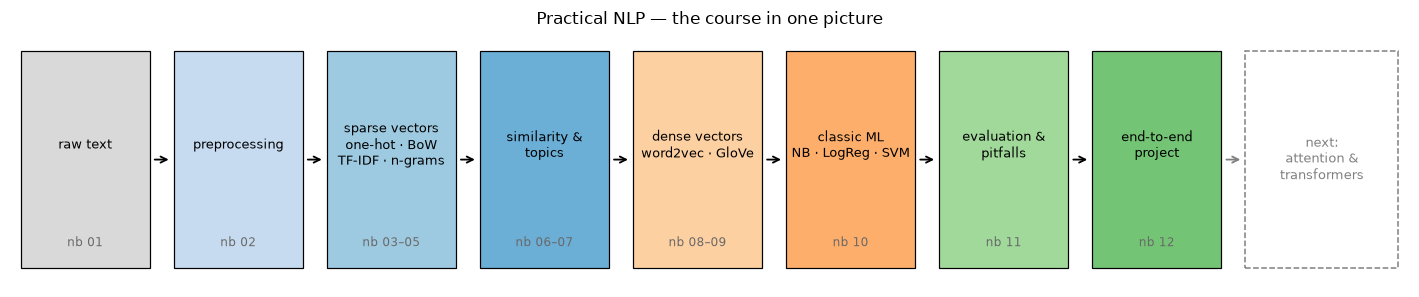

In [14]:
steps = [
    ("raw text", "01", "#d9d9d9"), ("preprocessing", "02", "#c6dbef"),
    ("sparse vectors\none-hot · BoW\nTF-IDF · n-grams", "03–05", "#9ecae1"),
    ("similarity &\ntopics", "06–07", "#6baed6"), ("dense vectors\nword2vec · GloVe", "08–09", "#fdd0a2"),
    ("classic ML\nNB · LogReg · SVM", "10", "#fdae6b"), ("evaluation &\npitfalls", "11", "#a1d99b"),
    ("end-to-end\nproject", "12", "#74c476"),
]
fig, ax = plt.subplots(figsize=(13, 2.8))
for k, (label, nbs, col) in enumerate(steps):
    x = k * 1.6
    ax.add_patch(plt.Rectangle((x, 0), 1.35, 1.2, fc=col, ec="black", lw=0.8))
    ax.text(x + 0.675, 0.68, label, ha="center", va="center", fontsize=8.5)
    ax.text(x + 0.675, 0.14, f"nb {nbs}", ha="center", va="center", fontsize=8, color="dimgrey")
    if k < len(steps) - 1:
        ax.annotate("", xy=(x + 1.58, 0.6), xytext=(x + 1.37, 0.6), arrowprops=dict(arrowstyle="->", lw=1.2))
ax.add_patch(plt.Rectangle((len(steps) * 1.6, 0), 1.6, 1.2, fc="white", ec="grey", ls="--"))
ax.text(len(steps) * 1.6 + 0.8, 0.6, "next:\nattention &\ntransformers", ha="center", va="center", fontsize=8.5, color="grey")
ax.annotate("", xy=(len(steps) * 1.6 - 0.02, 0.6), xytext=(len(steps) * 1.6 - 0.23, 0.6), arrowprops=dict(arrowstyle="->", lw=1.2, color="grey"))
ax.set_xlim(-0.1, len(steps) * 1.6 + 1.7)
ax.set_ylim(-0.1, 1.3)
ax.axis("off")
ax.set_title("Practical NLP — the course in one picture", fontsize=11)
fig.tight_layout()
fig.savefig(DOCS / "12_course_map.png", bbox_inches="tight")
plt.show()

## Exercises
**Exercise 1.** Apply the same recipe to the **4-category newsgroups**: a `Pipeline` of word TF-IDF
(applied to the raw text) and a Linear SVM, compared by 5-fold cross-validation on the official training set
against Naive Bayes, then evaluated once on the official test set with macro-F1.

In [15]:
# your code here

<details>
<summary><b>Show solution</b></summary>

The model is chosen by cross-validation on the training posts; the test set is used once, for the chosen model only.

```python
ng_tr, ng_te = nlp_course.load_newsgroups("train"), nlp_course.load_newsgroups("test")
cands = {"NB": make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, stop_words="english"), MultinomialNB(alpha=0.1)),
         "SVM": make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, stop_words="english"), LinearSVC())}
cv_ng = {n: cross_validate(p, ng_tr["text"], ng_tr["category"], cv=cv, scoring="f1_macro")["test_score"].mean()
         for n, p in cands.items()}
print("CV macro-F1:", {n: round(float(v), 3) for n, v in cv_ng.items()})
best = max(cv_ng, key=cv_ng.get)
p = cands[best].fit(ng_tr["text"], ng_tr["category"]).predict(ng_te["text"])
print(f"chosen: {best}  test macro-F1: {f1_score(ng_te['category'], p, average='macro'):.3f}")
```
</details>

In [16]:
ng_tr, ng_te = nlp_course.load_newsgroups("train"), nlp_course.load_newsgroups("test")
cands = {"NB": make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, stop_words="english"), MultinomialNB(alpha=0.1)),
         "SVM": make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, stop_words="english"), LinearSVC())}
cv_ng = {n: cross_validate(p, ng_tr["text"], ng_tr["category"], cv=cv, scoring="f1_macro")["test_score"].mean()
         for n, p in cands.items()}
print("CV macro-F1:", {n: round(float(v), 3) for n, v in cv_ng.items()})
best = max(cv_ng, key=cv_ng.get)
p = cands[best].fit(ng_tr["text"], ng_tr["category"]).predict(ng_te["text"])
print(f"chosen: {best}  test macro-F1: {f1_score(ng_te['category'], p, average='macro'):.3f}")

CV macro-F1: {'NB': 0.91, 'SVM': 0.9}


chosen: NB  test macro-F1: 0.886


**Exercise 2.** Suppose users accept that about **1% of real messages** end up in the spam folder if more
spam is caught. Choose a decision threshold on `final.decision_function` such that 1% of ham would be flagged,
using only **out-of-fold** scores on the training set (`cross_val_predict(..., method="decision_function")`).
Then apply that threshold to the test set and report how many ham were flagged and how much spam was caught.

In [17]:
# your code here

<details>
<summary><b>Show solution</b></summary>

The threshold is chosen on out-of-fold training scores, so the test set stays untouched. It comes out below the default of 0: on the test set it flags 10 of 904 real messages (about 1%, as planned) instead of 1, and catches 128 of 131 spam instead of 122.

```python
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(final, X_train, y_train, cv=cv, method="decision_function")
thr = np.quantile(oof[y_train == 0], 0.99)          # 99% of training ham scores fall below this
s_test = final.decision_function(X_test)
p_thr = (s_test > thr).astype(int)
print(f"threshold {thr:.3f}  (default is 0)")
print(f"test: ham flagged {((p_thr == 1) & (y_test == 0)).sum()} of {(y_test == 0).sum()}, "
      f"spam caught {p_thr[y_test == 1].sum()} of {(y_test == 1).sum()} (recall {recall_score(y_test, p_thr):.3f})")
```
</details>

In [18]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(final, X_train, y_train, cv=cv, method="decision_function")
thr = np.quantile(oof[y_train == 0], 0.99)          # 99% of training ham scores fall below this
s_test = final.decision_function(X_test)
p_thr = (s_test > thr).astype(int)
print(f"threshold {thr:.3f}  (default is 0)")
print(f"test: ham flagged {((p_thr == 1) & (y_test == 0)).sum()} of {(y_test == 0).sum()}, "
      f"spam caught {p_thr[y_test == 1].sum()} of {(y_test == 1).sum()} (recall {recall_score(y_test, p_thr):.3f})")

threshold -0.450  (default is 0)
test: ham flagged 10 of 904, spam caught 128 of 131 (recall 0.977)


**Exercise 3.** Write `explain(message, k=6)` that prints the `k` features of a single message that contribute
most to its spam score (feature value × weight), and use it on the second message of `new_messages`.

In [19]:
# your code here

<details>
<summary><b>Show solution</b></summary>

For a linear model the score is exactly the sum of these contributions plus the intercept, so the explanation is faithful.

```python
def explain(message, k=6):
    x = final[:-1].transform(pd.Series([message])).toarray().ravel()
    contrib = x * w
    idx = np.argsort(-np.abs(contrib))[:k]
    print(f"score {contrib.sum() + final[-1].intercept_[0]:+.3f} for: {message[:70]}")
    for i in idx:
        print(f"   {names[i]:<28} {contrib[i]:+.3f}")
explain(new_messages[1])
```
</details>

In [20]:
def explain(message, k=6):
    x = final[:-1].transform(pd.Series([message])).toarray().ravel()
    contrib = x * w
    idx = np.argsort(-np.abs(contrib))[:k]
    print(f"score {contrib.sum() + final[-1].intercept_[0]:+.3f} for: {message[:70]}")
    for i in idx:
        print(f"   {names[i]:<28} {contrib[i]:+.3f}")
explain(new_messages[1])

score +1.482 for: CONGRATULATIONS! You have won a £500 voucher. Text CLAIM to 81010 now!
   word__text                   +0.229
   word__have won               +0.202
   word__you have               +0.190
   word__won                    +0.182
   word__claim                  +0.140
   word__now                    +0.089


## Summary
- A sound project protocol: **de-duplicate → lock away a test set → baselines → cross-validated model
  selection and tuning on the training set → evaluate once → read the errors → explain → save the pipeline.**
- Word + character TF-IDF in one `Pipeline` with a linear classifier is a strong, fast and interpretable text
  classifier — and the first thing to try on a new text problem.
- The whole course in one line: *clean the text, choose a representation, train a simple model, and evaluate
  it honestly.*

## Where to go next
You now have the classical foundations of NLP. The natural next step is **neural models that read words in
context** — where the vector for "bank" depends on the sentence it appears in:

- **[attention-explained](https://github.com/hentablihamza/attention-explained)** — the companion course: the
  attention mechanism and transformers, built step by step from the ideas in this course (vectors, dot-product
  similarity, softmax, weighted averages).
- *Speech and Language Processing* by Dan Jurafsky and James H. Martin (free draft online) — the reference
  textbook for everything in this course and beyond.
- The scikit-learn user guide on [working with text data](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html)
  and the [gensim documentation](https://radimrehurek.com/gensim/) — to go deeper with the tools used here.

Thank you for following the course — and good luck with your own text projects!